In [11]:
!python -m pip install streamlit pandas scikit-learn matplotlib wordcloud openpyxl

  Obtaining dependency information for wordcloud from https://files.pythonhosted.org/packages/45/70/0041966d469dec79036ad3962b83b007004b842531ee7c41bdba61310eb6/wordcloud-1.9.6-cp311-cp311-win_amd64.whl.metadata
   ---------------------------------------- 0.0/306.1 kB ? eta -:--:--
   ---------------------------------------- 0.0/306.1 kB ? eta -:--:--
   - -------------------------------------- 10.2/306.1 kB ? eta -:--:--
   ----- --------------------------------- 41.0/306.1 kB 393.8 kB/s eta 0:00:01
   ---------------- ----------------------- 122.9/306.1 kB 1.0 MB/s eta 0:00:01
   -------------------------- ------------- 204.8/306.1 kB 1.4 MB/s eta 0:00:01
   -------------------------------------- - 297.0/306.1 kB 1.4 MB/s eta 0:00:01
   ---------------------------------------- 306.1/306.1 kB 1.4 MB/s eta 0:00:00


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [12]:
import os, re, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)

%matplotlib inline


In [13]:
# Ganti dengan path lengkap jika file tidak berada di folder yang sama dengan notebook, contoh:
# FILE = r"C:\\Users\\NamaAnda\\Documents\\tweet_data_kesehatan.xlsx"
FILE = r"C:\Users\ASUS\OneDrive\Documents\Analisis sentimen menggunakan Neural Network\tweet_data.csv"

if not os.path.exists(FILE):                      # cari otomatis di sub-folder
    ketemu = glob.glob("**/" + os.path.basename(FILE), recursive=True)
    if not ketemu:
        raise FileNotFoundError(f"{FILE} tidak ditemukan. Folder kerja: {os.getcwd()}")
    FILE = ketemu[0]

df = pd.read_excel(FILE, sheet_name="tweet_data") if FILE.endswith(".xlsx") else pd.read_csv(FILE)
df = df[["created_at", "username", "full_text"]]
df.to_csv("tweet_data.csv", index=False, encoding="utf-8")   # simpan sebagai tweet_data.csv

print("File        :", FILE)
print("Jumlah data :", len(df), "(minimal 300 -> OK)" if len(df) >= 300 else "(KURANG dari 300!)")
print("Kolom       :", list(df.columns))
df.head()

File        : C:\Users\ASUS\OneDrive\Documents\Analisis sentimen menggunakan Neural Network\tweet_data.csv
Jumlah data : 1200 (minimal 300 -> OK)
Kolom       : ['created_at', 'username', 'full_text']


,created_at,username,full_text
0,2026-08-01 02:06:28,nakes_borneo98,RT @kabar_news95: Sistem pendaftaran donor dar...
1,2026-08-01 03:53:59,bapak_pontianak816,Pemerintah Banjarmasin menggelar rapat koordin...
2,2026-08-01 04:05:11,bapak_nusantara422,"Syukur ibu saya sudah pulih dari flu, terima k..."
3,2026-08-01 06:25:26,warga_hari_ini336,Pemerintah Bandung menggelar rapat koordinasi ...
4,2026-08-01 09:43:00,dokter_hari_ini86,RT @sehat_indonesia982: Kemenkes merilis pedom...


In [14]:
def bersihkan_teks(teks):
    teks = str(teks)
    teks = re.sub(r"https?://\S+|www\.\S+", " ", teks)   # URL
    teks = re.sub(r"@\w+", " ", teks)                     # mention
    teks = re.sub(r"#\w+", " ", teks)                     # hashtag
    teks = re.sub(r"\d+", " ", teks)                      # angka
    teks = re.sub(r"[^a-zA-Z\s]", " ", teks)              # simbol, tanda baca, emoji
    teks = teks.lower()                                   # case folding
    teks = re.sub(r"\s+", " ", teks).strip()              # spasi berlebih
    return teks

df = df.dropna(subset=["full_text"]).drop_duplicates(subset="full_text")
df["clean_text"] = df["full_text"].apply(bersihkan_teks)
df = df[df["clean_text"] != ""].reset_index(drop=True)
df[["full_text", "clean_text"]].head()

,full_text,clean_text
0,RT @kabar_news95: Sistem pendaftaran donor dar...,rt sistem pendaftaran donor darah error terus ...
1,Pemerintah Banjarmasin menggelar rapat koordin...,pemerintah banjarmasin menggelar rapat koordin...
2,"Syukur ibu saya sudah pulih dari flu, terima k...",syukur ibu saya sudah pulih dari flu terima ka...
3,Pemerintah Bandung menggelar rapat koordinasi ...,pemerintah bandung menggelar rapat koordinasi ...
4,RT @sehat_indonesia982: Kemenkes merilis pedom...,rt kemenkes merilis pedoman baru tentang hiper...


In [15]:
KATA_POSITIF = [
    "aman", "lega", "selamat", "bantuan", "membantu", "pulih", "sehat", "membaik",
    "sembuh", "berhasil", "sigap", "ramah", "cepat", "bagus", "bersih", "gratis",
    "terjangkau", "syukur", "alhamdulillah", "terima", "kasih", "apresiasi", "peduli",
    "semangat", "salut", "praktis", "memudahkan", "senang", "pahlawan", "tersedia",
    "sabar", "jelas",
]
KATA_NEGATIF = [
    "parah", "kecewa", "langka", "sengsara", "resah", "takut", "darurat", "buruk",
    "judes", "terlantar", "ditolak", "ribet", "mengecewakan", "kritis", "bahaya",
    "kotor", "tercemar", "mahal", "rugi", "sedih", "error", "gagal", "kesal", "tutup",
    "marah", "hoaks", "korban", "sakit", "penuh", "sesak", "menunda", "kekurangan",
    "meningkat", "naik",
]

def hitung(teks, daftar):
    # cocokkan kata utuh (agar "sehat" tidak ikut terhitung pada "kesehatan")
    return sum(len(re.findall(r"\b" + re.escape(k) + r"\b", teks)) for k in daftar)

def beri_label(teks_bersih):
    pos = hitung(teks_bersih, KATA_POSITIF)
    neg = hitung(teks_bersih, KATA_NEGATIF)
    if pos > neg:
        return "positif"
    if neg > pos:
        return "negatif"
    return "netral"

df["sentimen"] = df["clean_text"].apply(beri_label)
df[["clean_text", "sentimen"]].head(10)

,clean_text,sentimen
0,rt sistem pendaftaran donor darah error terus ...,negatif
1,pemerintah banjarmasin menggelar rapat koordin...,netral
2,syukur ibu saya sudah pulih dari flu terima ka...,positif
3,pemerintah bandung menggelar rapat koordinasi ...,netral
4,rt kemenkes merilis pedoman baru tentang hiper...,netral
5,rt pemerintah banjarmasin menggelar rapat koor...,netral
6,lega banget hasil lab aman dan bidan menjelask...,positif
7,kasus hipertensi meningkat di palembang warga ...,negatif
8,rt syukur ibu saya sudah pulih dari hipertensi...,positif
9,rt salut untuk apoteker di singkawang sigap me...,positif


sentimen
positif    421
netral     291
negatif    488
Name: count, dtype: int64


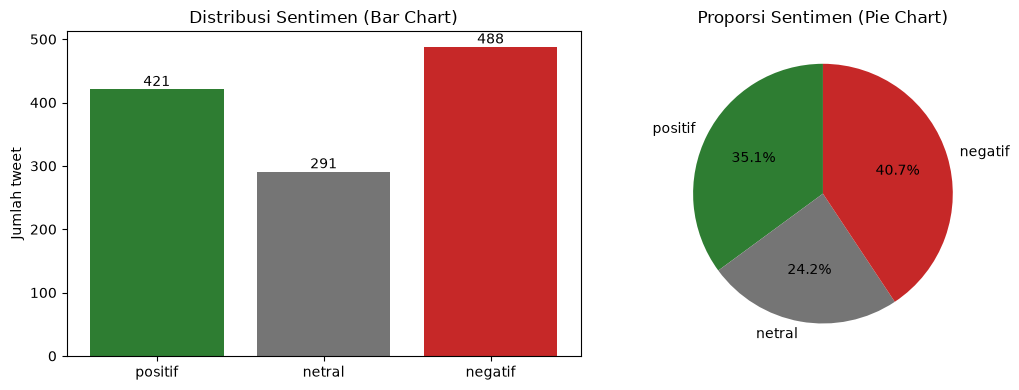

In [16]:
LABELS = ["positif", "netral", "negatif"]
WARNA = {"positif": "#2e7d32", "netral": "#757575", "negatif": "#c62828"}

dist = df["sentimen"].value_counts().reindex(LABELS).fillna(0).astype(int)
print(dist)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

bars = axes[0].bar(dist.index, dist.values, color=[WARNA[l] for l in dist.index])
axes[0].bar_label(bars)
axes[0].set_title("Distribusi Sentimen (Bar Chart)")
axes[0].set_ylabel("Jumlah tweet")

axes[1].pie(dist.values, labels=dist.index, autopct="%1.1f%%", startangle=90,
            colors=[WARNA[l] for l in dist.index])
axes[1].set_title("Proporsi Sentimen (Pie Chart)")

plt.tight_layout()
plt.show()

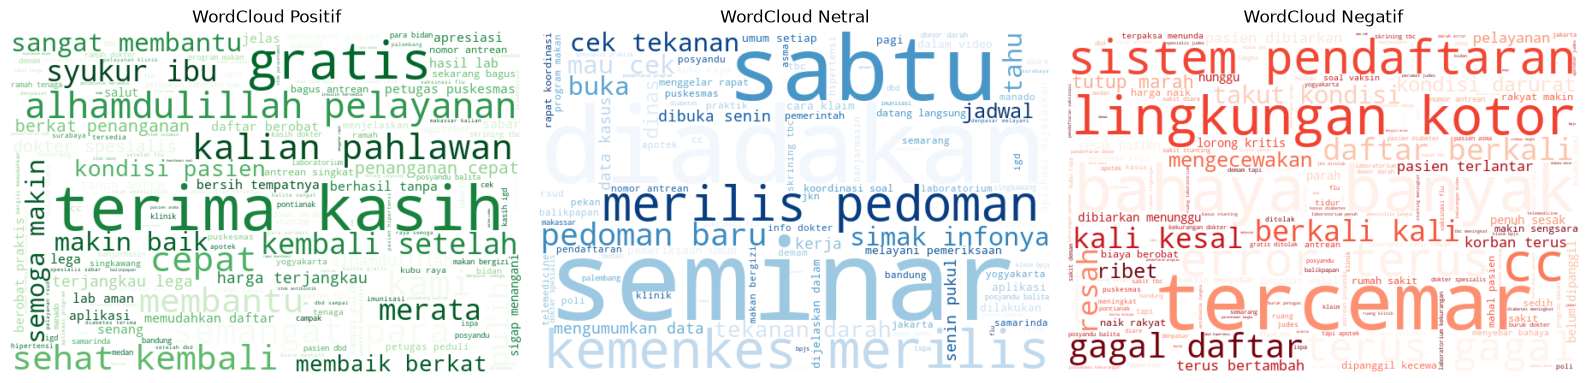

In [17]:
STOPWORDS = {
    "yang", "di", "dan", "ini", "itu", "ada", "untuk", "dengan", "dari", "pada",
    "adalah", "ke", "oleh", "dapat", "mulai", "rt", "yg", "saya", "kita", "juga",
    "sudah", "lagi", "jadi", "karena", "atau", "akan", "bisa", "sih", "nya",
    # kata umum yang muncul di semua kelas dan tidak membedakan sentimen
    "kesehatan", "banget", "warga", "anak", "hari", "jam", "tentang", "lewat",
}
CMAP = {"positif": "Greens", "netral": "Blues", "negatif": "Reds"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, lab in zip(axes, LABELS):
    teks_kelas = " ".join(df.loc[df["sentimen"] == lab, "clean_text"])
    ax.set_title(f"WordCloud {lab.capitalize()}")
    ax.axis("off")
    if not teks_kelas.strip():
        continue
    wc = WordCloud(width=600, height=400, background_color="white",
                   colormap=CMAP[lab], stopwords=STOPWORDS,
                   random_state=1).generate(teks_kelas)
    ax.imshow(wc, interpolation="bilinear")
plt.tight_layout()
plt.show()

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"], df["sentimen"],
    test_size=0.2, random_state=42, stratify=df["sentimen"]
)
print("Data latih:", len(X_train), "| Data uji:", len(X_test))

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

mlp = MLPClassifier(
    hidden_layer_sizes=(100,),
    activation="relu",
    solver="adam",
    max_iter=300,
    random_state=42,
)
mlp.fit(X_train_tfidf, y_train)
y_pred = mlp.predict(X_test_tfidf)
print("Pelatihan selesai. Iterasi:", mlp.n_iter_)

Data latih: 960 | Data uji: 240
Pelatihan selesai. Iterasi: 85


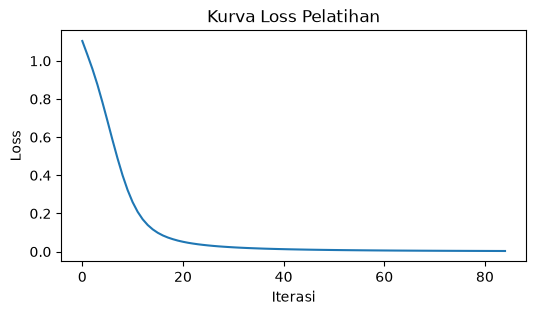

In [19]:
plt.figure(figsize=(6, 3))
plt.plot(mlp.loss_curve_)
plt.title("Kurva Loss Pelatihan")
plt.xlabel("Iterasi")
plt.ylabel("Loss")
plt.show()

In [20]:
kelas = [l for l in LABELS if l in set(y_test)]

acc = accuracy_score(y_test, y_pred)
prec, rec, f1, sup = precision_recall_fscore_support(
    y_test, y_pred, labels=kelas, zero_division=0)
p_m, r_m, f_m, _ = precision_recall_fscore_support(
    y_test, y_pred, average="macro", zero_division=0)

print(f"Akurasi          : {acc:.4f}")
print(f"Presisi (macro)  : {p_m:.4f}")
print(f"Recall (macro)   : {r_m:.4f}")
print(f"F1-Score (macro) : {f_m:.4f}\n")

tabel = pd.DataFrame({"Presisi": prec, "Recall": rec, "F1-Score": f1, "Support": sup},
                     index=kelas)
display(tabel.round(4))

print(classification_report(y_test, y_pred, labels=kelas, zero_division=0))

Akurasi          : 1.0000
Presisi (macro)  : 1.0000
Recall (macro)   : 1.0000
F1-Score (macro) : 1.0000



,Presisi,Recall,F1-Score,Support
positif,1.0,1.0,1.0,84
netral,1.0,1.0,1.0,58
negatif,1.0,1.0,1.0,98


              precision    recall  f1-score   support

     positif       1.00      1.00      1.00        84
      netral       1.00      1.00      1.00        58
     negatif       1.00      1.00      1.00        98

    accuracy                           1.00       240
   macro avg       1.00      1.00      1.00       240
weighted avg       1.00      1.00      1.00       240



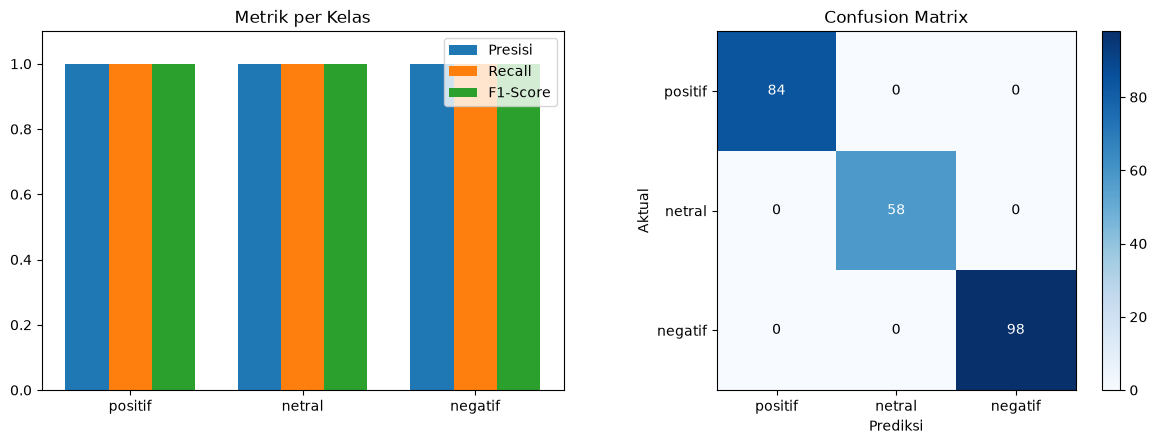

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Grafik metrik per kelas
x = np.arange(len(kelas)); w = 0.25
axes[0].bar(x - w, prec, w, label="Presisi")
axes[0].bar(x,     rec,  w, label="Recall")
axes[0].bar(x + w, f1,   w, label="F1-Score")
axes[0].set_xticks(x); axes[0].set_xticklabels(kelas)
axes[0].set_ylim(0, 1.1)
axes[0].set_title("Metrik per Kelas")
axes[0].legend()

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=kelas)
im = axes[1].imshow(cm, cmap="Blues")
axes[1].set_xticks(range(len(kelas))); axes[1].set_yticks(range(len(kelas)))
axes[1].set_xticklabels(kelas); axes[1].set_yticklabels(kelas)
axes[1].set_xlabel("Prediksi"); axes[1].set_ylabel("Aktual")
axes[1].set_title("Confusion Matrix")
for i in range(len(kelas)):
    for j in range(len(kelas)):
        axes[1].text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
fig.colorbar(im, ax=axes[1])

plt.tight_layout()
plt.show()

In [22]:
EMOJI = {"positif": "😊", "netral": "😐", "negatif": "😠"}

def prediksi_sentimen(teks):
    bersih = bersihkan_teks(teks)
    if not bersih:
        print("Teks kosong setelah dibersihkan.")
        return
    vec = tfidf.transform([bersih])
    hasil = mlp.predict(vec)[0]
    proba = mlp.predict_proba(vec)[0]

    print("Teks asli      :", teks)
    print("Setelah cleansing:", bersih)
    print(f"\nHasil prediksi : {EMOJI[hasil]} {hasil.upper()}\n")
    for c, p in sorted(zip(mlp.classes_, proba), key=lambda t: -t[1]):
        print(f"  {EMOJI[c]} {c:<8} {p:.2%}")

teks_baru = "Pelayanan puskesmas hari ini cepat dan ramah, pasien merasa lega"
prediksi_sentimen(teks_baru)

Teks asli      : Pelayanan puskesmas hari ini cepat dan ramah, pasien merasa lega
Setelah cleansing: pelayanan puskesmas hari ini cepat dan ramah pasien merasa lega

Hasil prediksi : 😊 POSITIF

  😊 positif  99.46%
  😠 negatif  0.30%
  😐 netral   0.24%


In [23]:
# Coba beberapa contoh sekaligus
contoh = [
    "Antrean rumah sakit parah, obat langka dan pasien resah",
    "Jadwal imunisasi anak dibuka Senin pukul 08.00 di posyandu",
    "Anak saya sudah pulih, terima kasih dokter dan perawat yang sabar",
]
for t in contoh:
    prediksi_sentimen(t)
    print("-" * 50)

Teks asli      : Antrean rumah sakit parah, obat langka dan pasien resah
Setelah cleansing: antrean rumah sakit parah obat langka dan pasien resah

Hasil prediksi : 😠 NEGATIF

  😠 negatif  99.75%
  😊 positif  0.19%
  😐 netral   0.06%
--------------------------------------------------
Teks asli      : Jadwal imunisasi anak dibuka Senin pukul 08.00 di posyandu
Setelah cleansing: jadwal imunisasi anak dibuka senin pukul di posyandu

Hasil prediksi : 😐 NETRAL

  😐 netral   99.65%
  😠 negatif  0.20%
  😊 positif  0.16%
--------------------------------------------------
Teks asli      : Anak saya sudah pulih, terima kasih dokter dan perawat yang sabar
Setelah cleansing: anak saya sudah pulih terima kasih dokter dan perawat yang sabar

Hasil prediksi : 😊 POSITIF

  😊 positif  99.40%
  😠 negatif  0.37%
  😐 netral   0.23%
--------------------------------------------------
